# Studi komparatif model generatif · Fashion-MNIST

Enam model PyTorch, lima eksperimen MLP, dan lima figur untuk tugas D6421. PDF tugas §2–§7 menentukan prosedur dan luaran. Slide Sesi 06 dan 07 menjelaskan model dan loss.

Notebook ini merangkum dan mengeksekusi ulang hasil referensi lokal berbantuan AI. Ketentuan PDF hlm. 6 menempatkan AI sebagai referensi sintaks dan dokumentasi. Gunakan bukti di sini untuk memeriksa implementasi dan menulis pembahasan mandiri.

## 1. Data, seed, dan partisi

In [1]:
import math
from pathlib import Path
from hashlib import sha256
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from skimage.metrics import structural_similarity
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST
from torchvision.utils import make_grid

TRAIN, REPLAY_FID = False, False
SEED, BATCH = 42, 128
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
METRICS = ROOT / "results/metrics"
OUT = ROOT / "results" / ("training" if TRAIN else "review")
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
np.random.seed(SEED)
torch.manual_seed(SEED)

try:
    official = [FashionMNIST(ROOT / "data", train=part) for part in (True, False)]
except RuntimeError:
    FashionMNIST.mirrors = ["https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"]
    official = [FashionMNIST(ROOT / "data", train=part, download=True) for part in (True, False)]
images = torch.cat([data.data for data in official]).unsqueeze(1).float() / 255
labels = torch.cat([data.targets for data in official])
classes = official[0].classes
split_path = METRICS / "fashion_mnist_seed42.npz"
split_hash = sha256(split_path.read_bytes()).hexdigest()
with np.load(split_path) as saved:
    indices = {part: torch.from_numpy(saved[part]) for part in ("train", "val", "test")}
assert [len(i) for i in indices.values()] == [56000, 7000, 7000]
assert torch.equal(torch.cat(list(indices.values())).sort().values, torch.arange(len(images)))
parts = {part: TensorDataset(images[i], labels[i]) for part, i in indices.items()}

def loader(part):
    return DataLoader(parts[part], BATCH, shuffle=part == "train",
                      generator=torch.Generator().manual_seed(SEED))

print(f"PyTorch {torch.__version__} | {torch.cuda.get_device_name() if DEVICE.type == 'cuda' else 'CPU'}")
display(pd.DataFrame({p: labels[i].bincount(minlength=10).tolist() for p, i in indices.items()}, index=classes))

PyTorch 2.11.0+cu128 | NVIDIA GeForce RTX 4060 Laptop GPU


,train,val,test
T-shirt/top,5600,700,700
Trouser,5600,700,700
Pullover,5600,700,700
Dress,5600,700,700
Coat,5600,700,700
Sandal,5600,700,700
Shirt,5600,700,700
Sneaker,5600,700,700
Bag,5600,700,700
Ankle boot,5600,700,700


## 2. Arsitektur dan loss

| Model | Alur tensor | Optimizer |
|---|---|---|
| Vanilla / Sparse AE | $784\to256\to64\to256\to784$, ReLU, keluaran sigmoid | Adam $10^{-3}$ |
| VAE | $784\to256\to(\mu,\log\sigma^2)$ berdimensi 64; $z\to256\to784$ | Adam $10^{-3}$ |
| Vanilla GAN | $G:100\to256\to512\to784$; $D:784\to512\to256\to1$ | Adam $2\cdot10^{-4}$, $(0.5,0.999)$ |
| DCGAN | $G:1\times1\to7^2\to14^2\to28^2$, kanal $100,64,32,1$; $D:28^2\to14^2\to7^2\to1$ | Adam $2\cdot10^{-4}$, $(0.5,0.999)$ |
| DDPM | $28^2\to14^2\to7^2\to14^2\to28^2$, skip aditif, embedding waktu 64 | Adam $2\cdot10^{-4}$ |
| MLP / decoder beku | $784\to256\to64\to10$ dan $64\to256\to784$, ReLU pada lapisan tersembunyi | Adam $10^{-3}$ |

- **Vanilla / Sparse AE** memakai $L=\operatorname{MSE}(x,\hat x)+\lambda\,\mathrm{mean}(|z|)$ dengan $\lambda=0$ dan $10^{-3}$.
- **VAE** memakai $z=\mu+\exp(\log\sigma^2/2)\odot\epsilon$, $\epsilon\sim\mathcal N(0,I)$. Loss per gambar ialah jumlah BCE piksel dan $\frac12\sum_j(\mu_j^2+\sigma_j^2-1-\log\sigma_j^2)$.
- **GAN** memakai $L_D=\operatorname{BCE}(D(x),1)+\operatorname{BCE}(D(G(z)),0)$ dan $L_G=\operatorname{BCE}(D(G(z)),1)$, semuanya berbasis logits. Output $G$ memakai tanh. DCGAN memakai konvolusi, LeakyReLU pada $D$, serta BatchNorm.
- **DDPM** memakai $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$ dan $L=\operatorname{MSE}(\epsilon,\epsilon_\theta(x_t,t))$. Sampel dimulai dari derau Gaussian dan mengikuti posterior reverse dengan $\hat x_0$ dibatasi ke $[-1,1]$ dalam sampler yang dipilih lewat validasi.
- **MLP** meminimalkan cross-entropy $-\log p_\theta(y\mid x)$. Decoder terpisah meminimalkan MSE rekonstruksi.

In [2]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                                     nn.Linear(256, 64), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784),
                                     nn.Sigmoid(), nn.Unflatten(1, (1, 28, 28)))

    def forward(self, x):
        return self.decoder(self.encoder(x))


class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.mean, self.logvar = nn.Linear(256, 64), nn.Linear(256, 64)
        self.decoder = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784),
                                     nn.Unflatten(1, (1, 28, 28)))

    def encode(self, x):
        h = self.encoder(x)
        return self.mean(h), self.logvar(h)

    def forward(self, x):
        return self.decoder(self.encode(x)[0]).sigmoid()


class GAN(nn.Module):
    def __init__(self, convolutional):
        super().__init__()
        if convolutional:
            self.generator = nn.Sequential(
                nn.Unflatten(1, (100, 1, 1)),
                nn.ConvTranspose2d(100, 64, 7, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
                nn.ConvTranspose2d(64, 32, 4, 2, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
                nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Tanh(),
            )
            self.discriminator = nn.Sequential(
                nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2),
                nn.Conv2d(32, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.LeakyReLU(0.2),
                nn.Conv2d(64, 1, 7), nn.Flatten(1),
            )
            for layer in self.modules():
                if isinstance(layer, (nn.Conv2d, nn.ConvTranspose2d, nn.BatchNorm2d)):
                    nn.init.normal_(layer.weight, float(isinstance(layer, nn.BatchNorm2d)), 0.02)
                    if layer.bias is not None:
                        nn.init.zeros_(layer.bias)
        else:
            self.generator = nn.Sequential(
                nn.Linear(100, 256), nn.ReLU(), nn.Linear(256, 512), nn.ReLU(),
                nn.Linear(512, 784), nn.Tanh(), nn.Unflatten(1, (1, 28, 28)),
            )
            self.discriminator = nn.Sequential(
                nn.Flatten(), nn.Linear(784, 512), nn.LeakyReLU(0.2),
                nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Linear(256, 1),
            )


class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1, self.fc2, self.fc3 = nn.Linear(784, 256), nn.Linear(256, 64), nn.Linear(64, 10)

    def features(self, x):
        return self.fc2(self.fc1(x.flatten(1)).relu()).relu()

    def forward(self, x):
        return self.fc3(self.features(x))

In [3]:
class TimeBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, padding=1)
        self.norm = nn.GroupNorm(4, channels)
        self.time = nn.Linear(64, channels)

    def forward(self, x, t):
        return F.silu(self.norm(self.conv(x)) + self.time(t)[:, :, None, None])


class DDPM(nn.Module):
    steps = 200

    def __init__(self):
        super().__init__()
        t = torch.linspace(0, 1, self.steps + 1, dtype=torch.float64)
        cosine = ((t + 0.008) / 1.008 * math.pi / 2).cos().square()
        beta = F.pad((1 - cosine[1:] / cosine[:-1]).clamp(1e-8, 0.999), (1, 0))
        alpha, abar = 1 - beta, (1 - beta).cumprod(0)
        var = (1 - abar[1:]).clamp_min(1e-20)
        angle = torch.arange(self.steps + 1)[:, None] * (-math.log(10000) * torch.arange(32) / 32).exp()
        buffers = {
            "embeddings": torch.cat((angle.sin(), angle.cos()), dim=1),
            "alpha_bar": abar, "clean_scale": abar.sqrt(), "noise_scale": (1 - abar).sqrt(),
            "posterior_std": F.pad((beta[1:] * (1 - abar[:-1]) / var).sqrt(), (1, 0)),
            "posterior_x0": F.pad(beta[1:] * abar[:-1].sqrt() / var, (1, 0)),
            "posterior_xt": F.pad(alpha[1:].sqrt() * (1 - abar[:-1]) / var, (1, 0)),
        }
        for name, values in buffers.items():
            self.register_buffer(name, values.float(), persistent=not name.startswith("posterior_x"))
        self.time = nn.Sequential(nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 64))
        self.stem = nn.Conv2d(1, 16, 3, padding=1)
        self.encode_28, self.encode_14, self.middle = TimeBlock(16), TimeBlock(32), TimeBlock(64)
        self.down_14, self.down_7 = nn.Conv2d(16, 32, 4, 2, 1), nn.Conv2d(32, 64, 4, 2, 1)
        self.up_14, self.up_28 = nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ConvTranspose2d(32, 16, 4, 2, 1)
        self.decode_14, self.decode_28 = TimeBlock(32), TimeBlock(16)
        self.output = nn.Conv2d(16, 1, 3, padding=1)

    def forward(self, x, step):
        t = self.time(self.embeddings[step])
        first = self.encode_28(self.stem(x.contiguous(memory_format=torch.channels_last)), t)
        second = self.encode_14(self.down_14(first), t)
        h = self.middle(self.down_7(second), t)
        h = self.decode_14(self.up_14(h) + second, t)
        return self.output(self.decode_28(self.up_28(h) + first, t))

    def objective(self, x):
        step = torch.randint(1, self.steps + 1, (len(x),), device=x.device)
        index = step[:, None, None, None]
        eps = torch.randn_like(x)
        noisy = self.clean_scale[index] * (2 * x - 1) + self.noise_scale[index] * eps
        return F.mse_loss(self(noisy, step), eps)

    def sample(self, x, rng, frames=None):
        for t in range(self.steps, 0, -1):
            if frames is not None and t in frames:
                frames[t] = x[0].clone()
            step = torch.full((len(x),), t, dtype=torch.long, device=x.device)
            clean = ((x - self.noise_scale[t] * self(x, step)) / self.clean_scale[t]).clamp(-1, 1)
            x = self.posterior_x0[t] * clean + self.posterior_xt[t] * x
            if t > 1:
                x = x + self.posterior_std[t] * torch.randn(x.shape, device=x.device, generator=rng)
        if frames is not None:
            frames[0] = x[0].clone()
        return (x / 2 + 0.5).clamp(0, 1)

## 3. Pilih hasil referensi atau latih ulang

$\texttt{TRAIN=False}$ memuat bobot yang dipilih dengan validasi dan histori run sebelumnya. $\texttt{TRAIN=True}$ memilih ulang AE/VAE, MLP dan decoder dari loss atau akurasi validation, serta GAN/DCGAN/DDPM dari FID validation kandidat. DDPM memakai sampler *clipped-x0* yang telah dipilih pada run referensi. Kedua mode memakai split yang sama. $\texttt{REPLAY_FID=True}$ menghitung ulang FID test dengan 5.000 citra real dan 5.000 sampel per model, Inception 2.048 fitur dan kanal grayscale direplikasi ke RGB.

In [4]:
NAMES = ("Vanilla AE", "Sparse AE", "VAE", "Vanilla GAN", "DCGAN", "DDPM")
EPOCHS = (30, 30, 30, 50, 50, 30)
GEN = NAMES[2:]
models = dict(zip(NAMES, (Autoencoder(), Autoencoder(), VAE(), GAN(False), GAN(True), DDPM())))
for model in models.values():
    model.to(DEVICE)
models["DDPM"].to(memory_format=torch.channels_last)
classifier = MLPClassifier().to(DEVICE)
decoder = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784),
                        nn.Sigmoid(), nn.Unflatten(1, (1, 28, 28))).to(DEVICE)

P2 = "phase2-seed42"
P3 = ("vanilla-gan-seed42", "dcgan-joint-seed42", "ddpm-seed42")
P4 = "mlp_classifier/phase4-mlp-seed42"
MODEL_FILES = (
    f"{P2}/vanilla_ae.pt", f"{P2}/sparse_ae.pt", f"{P2}/vae.pt",
    f"vanilla_gan/{P3[0]}/epoch-050.pt", f"dcgan/{P3[1]}/epoch-050.pt",
    f"ddpm/{P3[2]}/epoch-030.pt",
)
history, chosen = {}, {}

def load_reference(model, path):
    state = torch.load(ROOT / "results/checkpoints" / path, map_location="cpu", weights_only=True)
    meta = state.get("config", state)
    assert (meta["seed"], meta["batch_size"], meta["split_sha256"]) == (SEED, BATCH, split_hash)
    weights = state.get("model_state_dict", state.get("model"))
    if isinstance(model, DDPM):
        weights = {key: value for key, value in weights.items() if key not in {"reverse_scale", "predicted_scale"}}
    model.load_state_dict(weights)
    model.eval()
    return state["epoch"]

def rng(seed=SEED):
    return torch.Generator(device=DEVICE).manual_seed(seed)

def initial(name, n, generator):
    shape = (1, 28, 28) if name == "DDPM" else (64,) if name == "VAE" else (100,)
    return torch.randn((n, *shape), device=DEVICE, generator=generator)

def generate(name, z, generator=None):
    model = models[name]
    if name == "DDPM":
        return model.sample(z, generator)
    if name == "VAE":
        return model.decoder(z).sigmoid()
    return (model.generator(z) + 1) / 2

@torch.inference_mode()
def fid_reference(part, count):
    from torchmetrics.image.fid import FrechetInceptionDistance
    weights = ROOT / "data/torch-cache/weights-inception-2015-12-05-6726825d.pth"
    metric = FrechetInceptionDistance(
        feature=2048, normalize=True, antialias=True, reset_real_features=False,
        feature_extractor_weights_path=str(weights) if weights.is_file() else None,
    ).to(DEVICE).eval()
    x = parts[part].tensors[0]
    subset = torch.randperm(len(x), generator=torch.Generator().manual_seed(SEED))[:count]
    for batch in x[subset].split(64):
        metric.update(batch.to(DEVICE).repeat(1, 3, 1, 1), real=True)
    return metric

@torch.inference_mode()
def fid_score(name, metric, count):
    generator = rng()
    for start in range(0, count, 64):
        x = generate(name, initial(name, min(64, count - start), generator), generator)
        assert x.isfinite().all()
        metric.update(x.repeat(1, 3, 1, 1), real=False)
    value = metric.compute().item()
    metric.reset()
    assert math.isfinite(value)
    return value

In [5]:
def ae_loss(name, model, x, generator=None):
    if name == "VAE":
        mu, logvar = model.encode(x)
        eps = torch.randn(mu.shape, device=mu.device, generator=generator)
        logits = model.decoder(mu + (logvar / 2).exp() * eps)
        kl = (mu.square() + logvar.exp() - 1 - logvar).sum() / (2 * len(x))
        return F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x) + kl
    z = model.encoder(x)
    return F.mse_loss(model.decoder(z), x) + (0.001 if name == "Sparse AE" else 0) * z.abs().mean()

def update(loss, optimizer):
    if not loss.isfinite():
        raise FloatingPointError("Loss tidak finite.")
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

def bce(logits, real):
    return F.binary_cross_entropy_with_logits(logits, torch.full_like(logits, float(real)))

def gan_update(model, x, optimizers):
    g, d = model.generator, model.discriminator
    fake = g(torch.randn(len(x), 100, device=x.device))
    real = 2 * x - 1
    if model is models["DCGAN"]:
        real_logits, fake_logits = d(torch.cat((real, fake.detach()))).chunk(2)
    else:
        real_logits, fake_logits = d(real), d(fake.detach())
    loss_d = bce(real_logits, True) + bce(fake_logits, False)
    update(loss_d, optimizers[1])
    d.requires_grad_(False)
    try:
        loss_g = bce(d(fake), True)
        update(loss_g, optimizers[0])
    finally:
        d.requires_grad_(True)
    return {"loss_g": loss_g.detach(), "loss_d": loss_d.detach()}

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def validation(score):
    return sum(float(score(x.to(DEVICE), y.to(DEVICE))) * len(x)
               for x, y in loader("val")) / len(parts["val"])

def fit(name, model, epochs, objective, score, candidates=None):
    torch.manual_seed(SEED)
    loader_train = loader("train")
    is_gan = isinstance(model, GAN)
    lr = 2e-4 if is_gan or isinstance(model, DDPM) else 1e-3
    optimizers = ([torch.optim.Adam(net.parameters(), lr=lr, betas=(0.5, 0.999))
                   for net in (model.generator, model.discriminator)] if is_gan
                  else [torch.optim.Adam(model.parameters(), lr=lr)])
    rows, best = [], math.inf
    for epoch in range(1, epochs + 1):
        model.train()
        totals = {}
        sync()
        start = perf_counter()
        for x, y in loader_train:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if is_gan:
                batch = gan_update(model, x, optimizers)
            else:
                loss = objective(x, y)
                update(loss, optimizers[0])
                batch = {"loss": loss.detach()}
            for key, value in batch.items():
                totals[key] = totals.get(key, 0) + value * len(x)
        sync()
        row = {"epoch": epoch, "train_seconds": perf_counter() - start,
               **{k: float(v) / len(parts["train"]) for k, v in totals.items()}}
        model.eval()
        if candidates is None or epoch in candidates:
            value = score()
            if not math.isfinite(value):
                raise FloatingPointError(f"Skor validasi tidak finite untuk {name}.")
            row["validation"] = value
            if value < best:
                best, chosen[name] = value, epoch
                selected = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        rows.append(row)
        print(f"{name} {epoch}/{epochs}", {k: round(v, 4) for k, v in row.items() if k != "epoch"})
    model.load_state_dict(selected)
    history[name] = pd.DataFrame(rows)
    history[name].to_csv(OUT / f"{name}-history.csv", index=False)
    torch.save({"model": selected, "epoch": chosen[name], "seed": SEED,
                "batch_size": BATCH, "split_sha256": split_hash}, OUT / f"{name}.pt")

In [6]:
if TRAIN:
    valid_count = 1000
    valid_fid = fid_reference("val", valid_count)
    for name, epochs in zip(NAMES, EPOCHS):
        model = models[name]
        if name in NAMES[:3]:
            def objective(x, y):
                return ae_loss(name, model, x)

            def score():
                generator = rng()
                return validation(lambda x, y: ae_loss(name, model, x, generator) if name == "VAE"
                                  else F.mse_loss(model(x), x))

            fit(name, model, epochs, objective, score)
        else:
            objective = (lambda x, y: model.objective(x)) if name == "DDPM" else None
            candidates = (10, 20, 30) if name == "DDPM" else (15, 30, 50)
            fit(name, model, epochs, objective, lambda: fid_score(name, valid_fid, valid_count), candidates)
    del valid_fid
    fit("MLP", classifier, 40, lambda x, y: F.cross_entropy(classifier(x), y),
        lambda: validation(lambda x, y: -(classifier(x).argmax(1) == y).float().mean()))
    classifier.eval().requires_grad_(False)
    frozen = {k: v.clone() for k, v in classifier.state_dict().items()}
    fit("Decoder beku", decoder, 30, lambda x, y: F.mse_loss(decoder(classifier.features(x)), x),
        lambda: validation(lambda x, y: F.mse_loss(decoder(classifier.features(x)), x)))
    assert all(torch.equal(v, frozen[k]) for k, v in classifier.state_dict().items())
else:
    checkpoint_files = dict(zip(NAMES, MODEL_FILES)) | {
        "MLP": f"{P4}/classifier.pt", "Decoder beku": f"{P4}/decoder.pt",
    }
    for name, model in (models | {"MLP": classifier, "Decoder beku": decoder}).items():
        chosen[name] = load_reference(model, checkpoint_files[name])
    classifier.requires_grad_(False)
    for name, filename in zip(NAMES[:3], ("vanilla_ae", "sparse_ae", "vae")):
        history[name] = pd.read_csv(METRICS / P2 / f"{filename}-history.csv").rename(columns={"train_loss": "loss"})
    for name, run in zip(NAMES[3:], P3):
        history[name] = pd.read_csv(METRICS / "phase3" / run / "history.csv")

display(pd.Series(chosen, name="Epoch terpilih").to_frame())

,Epoch terpilih
Vanilla AE,29
Sparse AE,27
VAE,29
Vanilla GAN,50
DCGAN,50
DDPM,30
MLP,36
Decoder beku,30


## 4. Rekonstruksi, metrik test, dan pembuktian MLP

Tahap 1 mengukur akurasi MLP Cross-Entropy dan mengekstrak fitur setelah ReLU kedua. Tahap 2–3 memakai $W_3^\top,W_2^\top,W_1^\top$ dari kelas one-hot dan $W_2^\top,W_1^\top$ dari fitur citra. Batch adalah vektor baris, sehingga transpos diterapkan dengan perkalian z @ W. Tahap 4 membandingkan decoder dari fitur MLP beku dengan Vanilla AE, keduanya berdimensi 64. Tahap 5 mengambil $\mu$ dan $\sigma$ dari fitur test sesuai PDF §2.1 setelah pemilihan bobot, khusus untuk demonstrasi sampling.

Untuk $W_1\in\mathbb R^{256\times784}$, $\operatorname{rank}(W_1^\top W_1)\le256$, sehingga $W_1^\top W_1\ne I_{784}$. Vektor yang berbeda sebesar anggota nullspace punya proyeksi maju yang sama. ReLU juga memetakan semua nilai nonpositif ke nol. Cross-entropy memberi insentif mempertahankan fitur pembeda kelas. Kandungan informasi gambar yang masih tersisa diuji lewat decoder terpisah.

In [7]:
@torch.inference_mode()
def apply_batches(fn, x):
    return torch.cat([fn(batch.to(DEVICE)).cpu() for batch in x.split(BATCH)])

def paired_metrics(original, estimate):
    mse = (original - estimate).square().mean(dim=(1, 2, 3))
    psnr = (-10 * mse.log10()).mean()
    ssim = np.mean([structural_similarity(a[0], b[0], data_range=1.0, win_size=7)
                    for a, b in zip(original.numpy(), estimate.numpy())])
    return {"MSE": mse.mean().item(), "PSNR (dB)": psnr.item(), "SSIM": ssim}

test_x, test_y = parts["test"].tensors
recons = {name: apply_batches(models[name], test_x) for name in NAMES[:3]}
features = apply_batches(classifier.features, test_x)
predictions = apply_batches(classifier, test_x).argmax(1)
accuracy = (predictions == test_y).float().mean().item()
recons["Decoder beku"] = apply_batches(decoder, features)
reconstruction_table = pd.DataFrame({name: paired_metrics(test_x, x) for name, x in recons.items()}).T
assert not any(p.requires_grad for p in classifier.parameters()) and features.shape == (len(test_x), 64)
print(f"Akurasi test MLP · {accuracy:.2%} | target 88% {'terpenuhi' if accuracy >= 0.88 else 'belum tercapai'}")
display(reconstruction_table.round(6))
reconstruction_table.to_csv(OUT / "reconstruction.csv")

examples = torch.tensor([int((test_y == label).nonzero()[0]) for label in range(8)])
originals = test_x[examples]
with torch.inference_mode():
    w1, w2, w3 = (layer.weight for layer in (classifier.fc1, classifier.fc2, classifier.fc3))

    def transpose_image(z):
        return ((z @ w2).relu() @ w1).sigmoid().reshape(-1, 1, 28, 28).cpu()

    class_projection = transpose_image((F.one_hot(test_y[examples], 10).float().to(DEVICE) @ w3).relu())
    feature_projection = transpose_image(features[examples].to(DEVICE))
    gaussian = features.mean(0) + features.std(0, correction=0) * torch.randn(
        16, 64, generator=torch.Generator().manual_seed(SEED)
    )
    gaussian_samples = decoder(gaussian.to(DEVICE)).cpu()

latent_val = {}
for name in NAMES[:2]:
    z = apply_batches(models[name].encoder, parts["val"].tensors[0])
    latent_val[name] = {"Rerata |z|": z.abs().mean().item(),
                        "Fraksi |z| <= 0,001": (z.abs() <= 1e-3).float().mean().item()}
display(pd.DataFrame(latent_val).T.round(4))
print(f"Koordinat prior Gaussian MLP negatif · {(gaussian < 0).sum().item()}/{gaussian.numel()}")

Akurasi test MLP · 90.01% | target 88% terpenuhi


,MSE,PSNR (dB),SSIM
Vanilla AE,0.007794,22.136799,0.798563
Sparse AE,0.007970,22.028854,0.793199
VAE,0.012954,19.706738,0.709614
Decoder beku,0.017634,18.376781,0.659581


,Rerata |z|,"Fraksi |z| <= 0,001"
Vanilla AE,2.4288,0.2779
Sparse AE,0.4985,0.3020


Koordinat prior Gaussian MLP negatif · 235/1024


In [8]:
@torch.inference_mode()
def latency(fn, repeats):
    for _ in range(3):
        fn()
    timings = []
    for _ in range(repeats):
        sync()
        start = perf_counter()
        fn()
        sync()
        timings.append(1000 * (perf_counter() - start))
    return float(np.mean(timings))

stability = {
    "Vanilla AE": "MSE validasi minimum pada epoch terpilih",
    "Sparse AE": "MSE validasi minimum dengan penalti L1 saat training",
    "VAE": "BCE + KL validasi minimum pada epoch terpilih",
    "Vanilla GAN": "Loss G/D berubah sepanjang training",
    "DCGAN": "Loss G/D berubah sepanjang training",
    "DDPM": "Loss prediksi derau tercatat tiap epoch",
}
table = pd.DataFrame({
    "Laten / derau": [64, 64, 64, 100, 100, "1×28×28"],
    "Epoch": [f"{chosen[name]}/{len(history[name])}" for name in NAMES],
    "Detik/epoch": [history[name]["train_seconds"].mean() for name in NAMES],
    "Catatan training": [stability[name] for name in NAMES],
}, index=NAMES).join(reconstruction_table).rename_axis("Model")
if not TRAIN:
    ref_recon = pd.read_csv(METRICS / P2 / "comparison.csv").set_index("model")
    ref_generative = pd.read_csv(METRICS / "phase3/comparison.csv").set_index("model")
    table["Rekon. ms/64"] = ref_recon["reconstruction_ms_batch64"].set_axis(NAMES[:3])
    table["Gen. ms/64"] = ref_generative["latency_mean_ms_batch64"]
    table["FID test"] = ref_generative["test_fid"]
    prior_mlp = pd.read_csv(METRICS / "phase4/phase4-mlp-seed42/reconstruction.csv").iloc[0]
    columns = ["test_mse", "test_psnr_db", "test_ssim"]
    expected = np.vstack([ref_recon[columns].values, prior_mlp[columns].astype(float).values])
    np.testing.assert_allclose(reconstruction_table.to_numpy(), expected, rtol=2e-4, atol=2e-5)
    assert round(accuracy * len(test_y)) == 6301
    print("Metrik rekonstruksi dan akurasi cocok dengan hasil awal. Latensi berasal dari run RTX 4060 Laptop GPU.")
else:
    batch = test_x[:64].to(DEVICE)
    table["Rekon. ms/64"] = pd.Series({name: latency(lambda: models[name](batch), 20) for name in NAMES[:3]})
    gen_latency = {}
    for name in GEN:
        generator = rng()
        z = initial(name, 64, generator)
        gen_latency[name] = latency(lambda: generate(name, z, generator), 5 if name == "DDPM" else 20)
    table["Gen. ms/64"] = pd.Series(gen_latency)

if TRAIN or REPLAY_FID:
    test_count = 5000
    test_fid = fid_reference("test", test_count)
    replays = {}
    for name in GEN:
        replays[name] = fid_score(name, test_fid, test_count)
        print(f"FID test · {name} · {replays[name]:.4f}")
    table["FID test" if TRAIN else "FID hitung ulang"] = pd.Series(replays)
    del test_fid

table.to_csv(OUT / "comparison.csv")
display(table.round(4).fillna("N/A"))

Metrik rekonstruksi dan akurasi cocok dengan hasil awal. Latensi berasal dari run RTX 4060 Laptop GPU.


,Laten / derau,Epoch,Detik/epoch,Catatan training,MSE,PSNR (dB),SSIM,Rekon. ms/64,Gen. ms/64,FID test
Model,,,,,,,,,,
Vanilla AE,64,29/30,8.3626,MSE validasi minimum pada epoch terpilih,0.0078,22.1368,0.7986,0.4368,N/A,N/A
Sparse AE,64,27/30,8.0721,MSE validasi minimum dengan penalti L1 saat tr...,0.008,22.0289,0.7932,0.4024,N/A,N/A
VAE,64,29/30,8.2095,BCE + KL validasi minimum pada epoch terpilih,0.013,19.7067,0.7096,0.5681,0.3566,87.6866
Vanilla GAN,100,50/50,11.1426,Loss G/D berubah sepanjang training,N/A,N/A,N/A,N/A,0.3332,116.4706
DCGAN,100,50/50,17.9951,Loss G/D berubah sepanjang training,N/A,N/A,N/A,N/A,1.0112,36.9664
DDPM,1×28×28,30/30,18.4918,Loss prediksi derau tercatat tiap epoch,N/A,N/A,N/A,N/A,708.6073,56.1567


## 5. Lima figur pembanding

Citra rekonstruksi memakai indeks uji yang sama. Sampling memakai seed 42 (Figur 2). Untuk interpolasi, AE dan VAE mengodekan T-shirt/top dan Ankle boot pertama di test. Pada GAN unconditional, cari kandidat Gaussian yang paling dipercaya oleh MLP untuk masing-masing kelas. Label GAN adalah prediksi MLP. Periksa apakah sampel ujung mendukung interpretasi kelasnya.

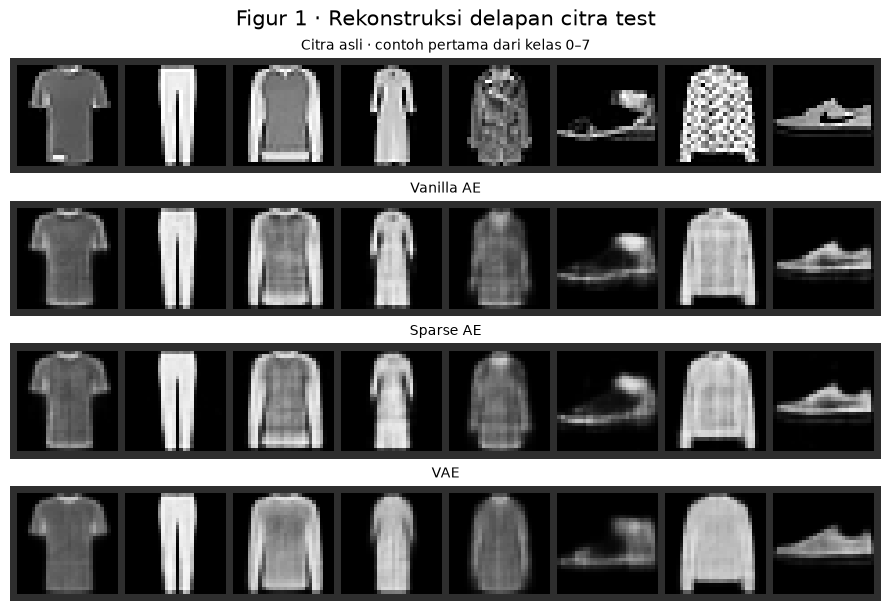

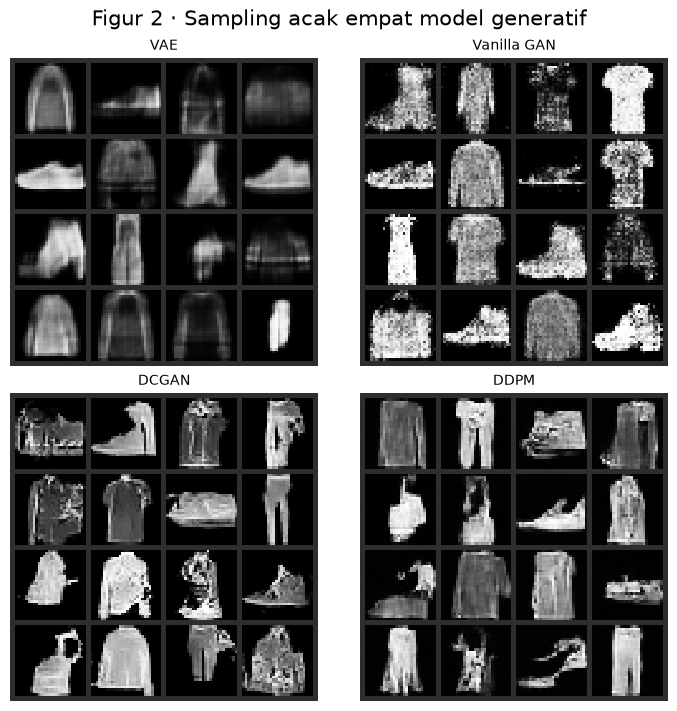

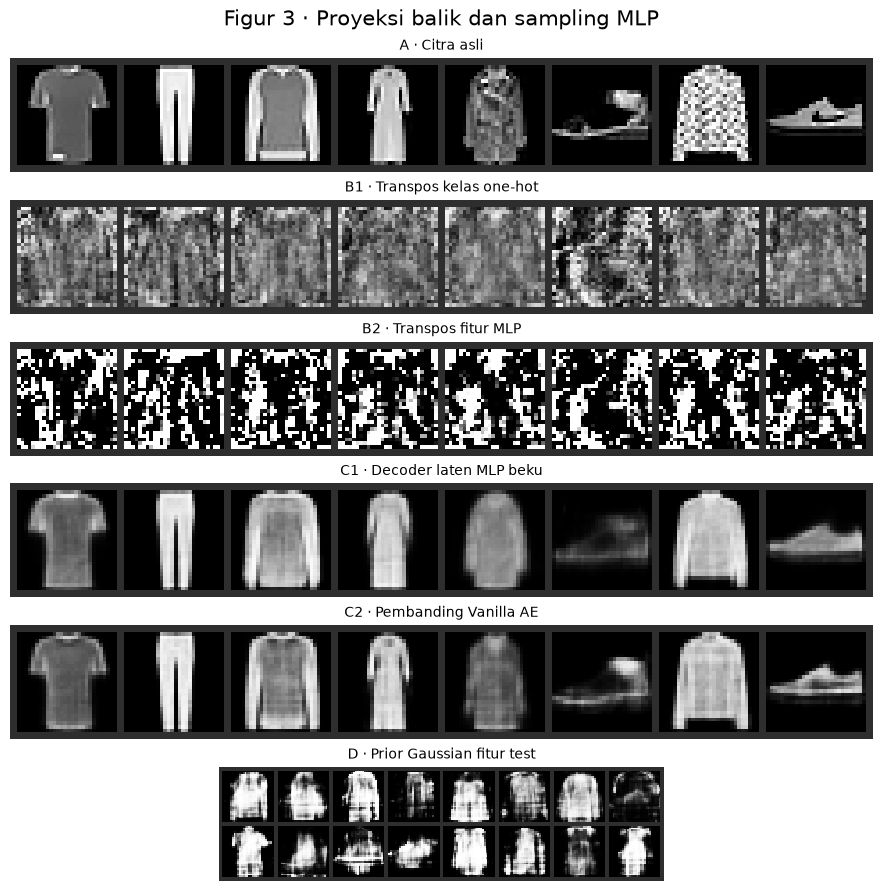

In [9]:
def panel(ax, x, label="", columns=8):
    assert x.isfinite().all() and x.min() >= 0 and x.max() <= 1
    grid = make_grid(x.cpu(), nrow=columns, padding=2, pad_value=0.18)[0]
    ax.imshow(grid, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(label, fontsize=10)
    ax.axis("off")

def show(fig, number, title):
    fig.suptitle(f"Figur {number} · {title}", fontsize=15)
    fig.savefig(OUT / f"figur-{number}.png", dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(fig)

fig, ax = plt.subplots(4, 1, figsize=(9, 6), layout="constrained")
panel(ax[0], originals, "Citra asli · contoh pertama dari kelas 0–7")
for row, name in enumerate(NAMES[:3], 1):
    panel(ax[row], recons[name][examples], name)
show(fig, 1, "Rekonstruksi delapan citra test")

fig, axes = plt.subplots(2, 2, figsize=(7, 7), layout="constrained")
with torch.inference_mode():
    for ax, name in zip(axes.flat, GEN):
        generator = rng()
        panel(ax, generate(name, initial(name, 16, generator), generator), name, columns=4)
show(fig, 2, "Sampling acak empat model generatif")

fig, ax = plt.subplots(6, 1, figsize=(9, 8.8), layout="constrained")
for axis, x, title in zip(ax, (
    originals, class_projection, feature_projection, recons["Decoder beku"][examples],
    recons["Vanilla AE"][examples], gaussian_samples,
), (
    "A · Citra asli", "B1 · Transpos kelas one-hot", "B2 · Transpos fitur MLP",
    "C1 · Decoder laten MLP beku", "C2 · Pembanding Vanilla AE", "D · Prior Gaussian fitur test",
)):
    panel(axis, x, title, columns=8)
show(fig, 3, "Proyeksi balik dan sampling MLP")

Vanilla GAN · noise [218, 52] · kelas prediksi [0, 9] · p(kelas target) [1. 1.]
DCGAN · noise [308, 251] · kelas prediksi [0, 9] · p(kelas target) [1. 1.]
Indeks test global [49223, 65946] | kelas target ['T-shirt/top', 'Ankle boot']


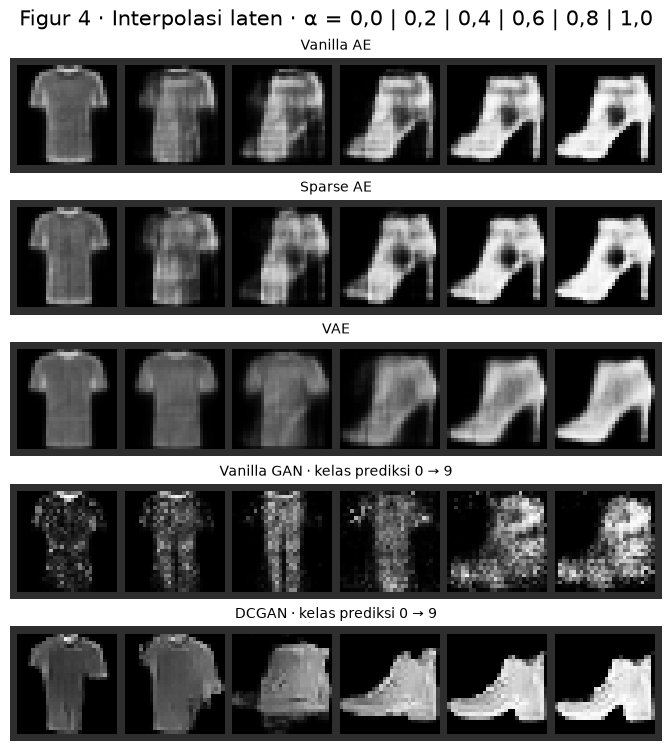

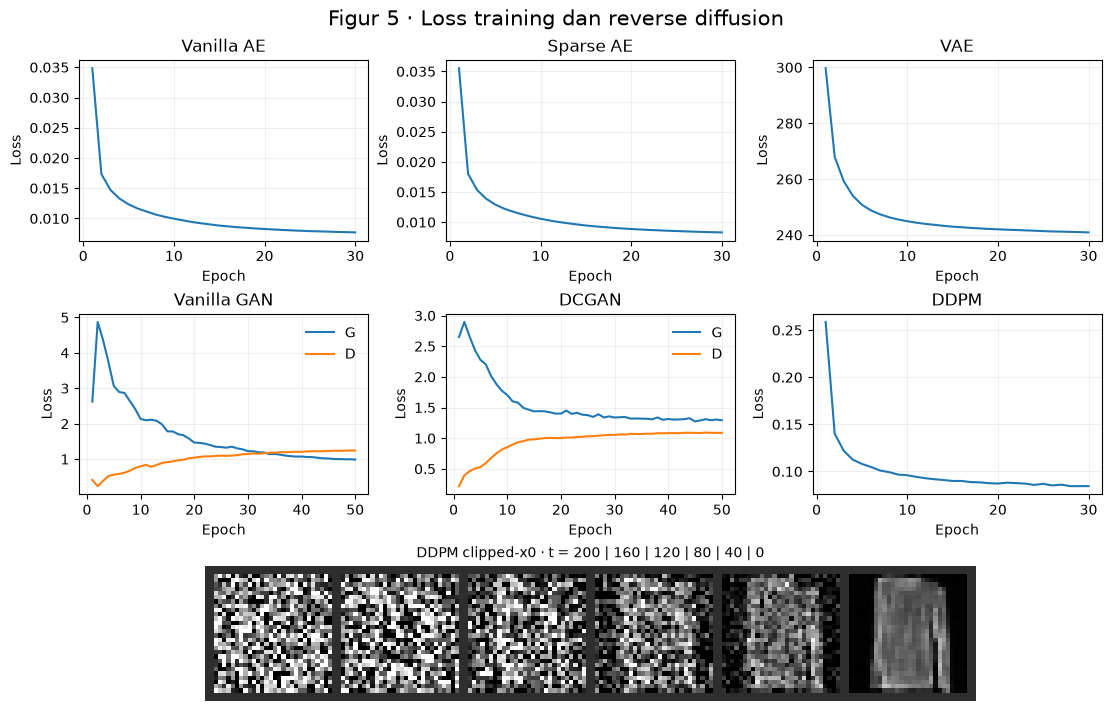

In [10]:
targets = (0, 9)
endpoint_ids = [int((test_y == label).nonzero()[0]) for label in targets]
alpha = torch.linspace(0, 1, 6, device=DEVICE)[:, None]
fig, axes = plt.subplots(5, 1, figsize=(8.5, 7.4), layout="constrained")
with torch.inference_mode():
    for ax, name in zip(axes, NAMES[:5]):
        model = models[name]
        if name in NAMES[:3]:
            x = test_x[endpoint_ids].to(DEVICE)
            z = model.encode(x)[0] if name == "VAE" else model.encoder(x)
            label = name
        else:
            candidate = initial(name, 512, rng())
            confidence = classifier(generate(name, candidate)).softmax(1)
            predicted = confidence.argmax(1)
            picks = []
            for c in targets:
                scores = confidence[:, c]
                if (predicted == c).any():
                    scores = scores.masked_fill(predicted != c, -1)
                picks.append(int(scores.argmax()))
            z = candidate[picks]
            actual = predicted[picks].tolist()
            scores = [float(confidence[i, c]) for i, c in zip(picks, targets)]
            label = f"{name} · kelas prediksi {actual[0]} → {actual[1]}"
            print(f"{name} · noise {picks} · kelas prediksi {actual} · p(kelas target) {np.round(scores, 3)}")
        path = torch.lerp(z[0], z[1], alpha)
        torch.testing.assert_close(path[[0, -1]], z)
        decode = model.decoder if name in NAMES[:2] else lambda z: generate(name, z)
        x = decode(path)
        torch.testing.assert_close(x[[0, -1]], decode(z), rtol=1e-4, atol=1e-6)
        panel(ax, x, label, columns=6)
print("Indeks test global", indices["test"][endpoint_ids].tolist(), "| kelas target", [classes[i] for i in targets])
show(fig, 4, "Interpolasi laten · α = 0,0 | 0,2 | 0,4 | 0,6 | 0,8 | 1,0")

fig = plt.figure(figsize=(11, 7), layout="constrained")
layout = fig.add_gridspec(3, 3, height_ratios=[2, 2, 1.5])
for i, name in enumerate(NAMES):
    ax = fig.add_subplot(layout[i // 3, i % 3])
    data = history[name]
    columns = ["loss_g", "loss_d"] if "loss_g" in data else ["loss"]
    for column in columns:
        ax.plot(data["epoch"], data[column], label={"loss_g": "G", "loss_d": "D", "loss": "Training"}[column])
    if len(columns) == 2:
        ax.legend(frameon=False)
    ax.set(title=name, xlabel="Epoch", ylabel="Loss")
    ax.grid(alpha=0.2)
frame_ids = [200, 160, 120, 80, 40, 0]
frames = dict.fromkeys(frame_ids)
with torch.inference_mode():
    generator = rng()
    models["DDPM"].sample(initial("DDPM", 1, generator), generator, frames)
trajectory = (torch.stack([frames[t] for t in frame_ids]) / 2 + 0.5).clamp(0, 1)
panel(fig.add_subplot(layout[2, :]), trajectory, "DDPM clipped-x0 · t = 200 | 160 | 120 | 80 | 40 | 0", columns=6)
show(fig, 5, "Loss training dan reverse diffusion")

## 6. Catatan analisis Q1–Q6

1. **Q1 · Fidelitas dan kualitas generatif.** Baca MSE, PSNR, dan SSIM dari pasangan citra test. Untuk distribusi sampel, bandingkan FID pada jumlah dan extractor yang sama. Pada run referensi, Vanilla AE unggul pada rekonstruksi dan DCGAN mendapat FID terendah yang tercatat. Dampak L1 terlihat pada penurunan magnitudo laten Sparse AE, dengan perubahan yang lebih kecil pada proporsi fitur mendekati nol.
2. **Q2 · Mengapa detail memudar.** Prediksi optimal terhadap squared error untuk tiap $z$ adalah $\mathbb E[x\mid z]$. Target BCE per piksel juga mengestimasi mean kondisional. Jika satu representasi mencakup beberapa posisi kontur, agregasi membentuk tepi lunak. Untuk minimax GAN asli dengan diskriminator optimal, objektif $G$ setara dengan konstanta ditambah $2D_{\rm JS}(p_{\rm data}\parallel p_g)$. Training di sini memakai varian generator non-saturating. Bandingkan tepi, tekstur, serta variasi di Figur 1–2 dan cek statistik sparse di atas.
3. **Q3 · Stabilitas dan Generative Trilemma.** Baca kurva dalam skala loss masing-masing. Diskriminator yang cepat mendominasi dapat melemahkan sinyal optimasi, dan osilasi pada loss G/D mengindikasikan dinamika adversarial. DCGAN menambahkan struktur lokal konvolusional dan BatchNorm. DDPM memprediksi target derau yang diketahui tetapi menjalankan 200 langkah saat sampling. Laporkan FID untuk kedekatan distribusi, latensi batch 64 untuk kecepatan, dan bentuk yang terlihat di grid sebagai bukti visual terbatas tentang cakupan mode. Kurva loss dan FID tunggal belum cukup untuk menyimpulkan mode collapse.
4. **Q4 · Interpolasi.** Enam titik di Figur 4 memakai formula $z_\alpha=(1-\alpha)z_A+\alpha z_B$. Laten AE deterministik dapat melewati wilayah yang jarang dikunjungi encoder karena objective hanya membatasi kode dari input training. KL VAE mendorong posterior mendekati prior. Itu membantu menata ruang sampling tanpa menjamin semua interpolasi halus. Sebutkan transisi spesifik pada pasangan yang ditampilkan dan cara pelabelan endpoint GAN.
5. **Q5 · Batas MLP.** Proyeksi transpos terikat rank dan ReLU. Decoder beku masih menampakkan informasi seperti siluet, dengan MSE lebih tinggi dari Vanilla AE pada dimensi laten sama. Distribusi Gaussian diagonal dapat menghasilkan koordinat negatif di luar dukungan fitur ReLU dan mengabaikan korelasi. Bedakan keterbatasan proyeksi, kualitas decoding, dan kegagalan asumsi prior sederhana.
6. **Q6 · Rekomendasi industri.** Vanilla AE merupakan baseline inspeksi karena error normal lebih rendah di benchmark ini. Untuk memilih antara Vanilla dan Sparse AE, ukur sensitivitas pada data cacat dan ambang yang sesuai. Untuk avatar interaktif, bandingkan generator satu langkah dengan latensi end-to-end di perangkat mobile, termasuk batch 1. Untuk aset kreatif, DCGAN unggul pada FID Fashion-MNIST run ini. DDPM layak dievaluasi bila anggaran sampling mengizinkan, dengan data dan resolusi target sebelum memutuskan.

**Kerangka laporan 10–12 halaman.** Gunakan identitas dan URL repositori di halaman judul, lalu susun teori dan diagram, eksperimen MLP, tabel test, lima figur bernomor, serta pembahasan Q1–Q6. Isi narasi dari pengamatan dan pengerjaan sendiri. Cantumkan seed tunggal, benchmark grayscale, dan perbedaan antara latensi GPU batch 64 dengan latensi aplikasi. FID memakai extractor Inception yang dilatih pada domain lain.

**Rujukan.** Panduan tugas D6421 §2–§7. *Autoencoders and Representation Learning*, Sesi 06, slide 6–13 dan 17–26. *Generative Models: GANs and Diffusion*, Sesi 07, slide 8–26. [Kingma & Welling · VAE](https://arxiv.org/abs/1312.6114), [Goodfellow dkk. · GAN](https://proceedings.neurips.cc/paper/2014/hash/f033ed80deb0234979a61f95710dbe25-Abstract.html), [Radford dkk. · DCGAN](https://arxiv.org/abs/1511.06434), [Ho dkk. · DDPM](https://papers.neurips.cc/paper/2020/hash/4c5bcfec8584af0d967f1ab10179ca4b-Abstract.html), [Heusel dkk. · FID](https://proceedings.neurips.cc/paper_files/paper/2017/hash/8a1d694707eb0fefe65871369074926d-Abstract.html).